In [1]:
import time
import re
import torch
from pathlib import Path
from PIL import Image, ImageDraw
from IPython.display import display
from transformers import AutoProcessor, AutoModelForMultimodalLM

# 与 Xiaomi-Lens-0 使用同一个数据集
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "datasets/几何简单测试").is_dir()), None)
assert ROOT is not None, "未找到 VLM-test 项目根目录"

MODEL_ID = "Qwen/Qwen3.5-4B"

# 高分辨率图片不压缩到 1024x1024；两张原图都低于 4MP
processor = AutoProcessor.from_pretrained(
    MODEL_ID,
    min_pixels=224 * 224,
    max_pixels=2048 * 2048,
)
model = AutoModelForMultimodalLM.from_pretrained(
    MODEL_ID,
    dtype=torch.bfloat16,
    device_map="auto",
)
model.eval()

print("模型:", MODEL_ID)
print("设备:", model.device)


/home/20261024_1/.local/share/mamba/envs/vlm-test/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Loading weights: 100%|██████████| 723/723 [00:04<00:00, 157.44it/s]


模型: Qwen/Qwen3.5-4B
设备: cuda:0


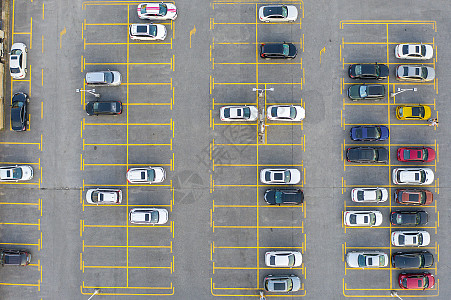

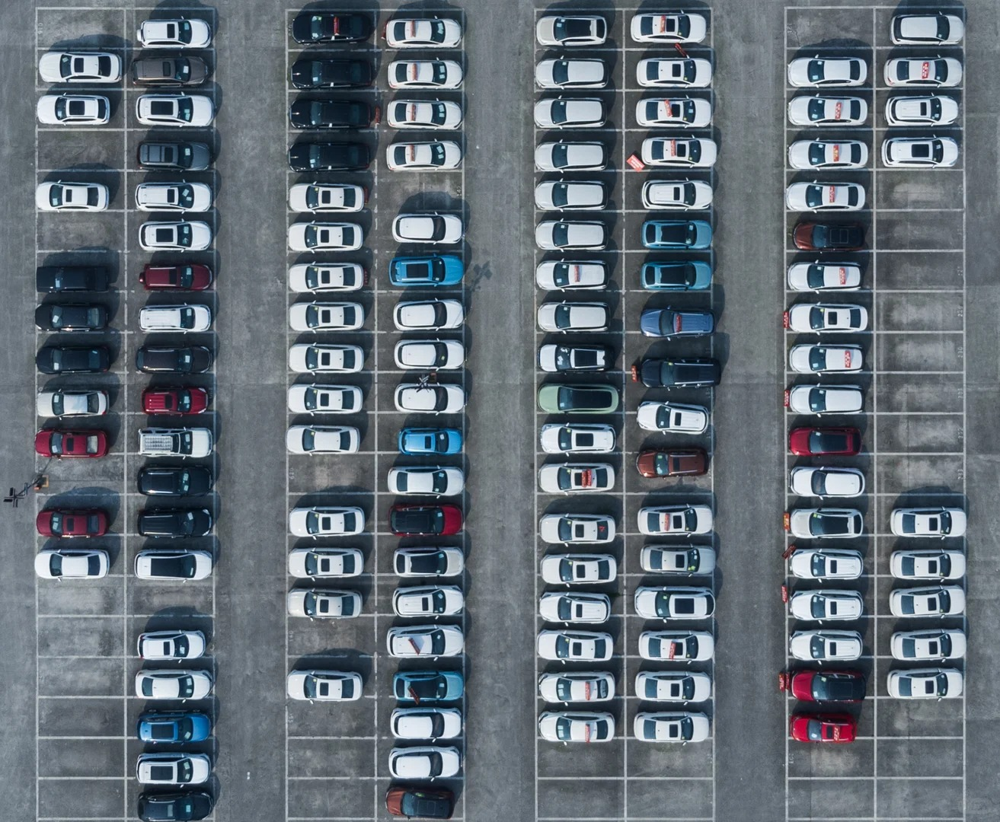

In [2]:
DATA_DIR = ROOT / "datasets/几何简单测试"

img1 = Image.open(DATA_DIR / "停车场图1.png").convert("RGB")
img2 = Image.open(DATA_DIR / "停车场图2.jpg").convert("RGB")

display(img1, img2)

In [3]:
# Qwen3.5-4B 通过文本输出 bbox；没有 Xiaomi-Lens-0 专用的像素 Mask 解码器。
# 框坐标遵循 Qwen3.5 的 0~1000 归一化坐标约定。


def parse_boxes(text):
    patterns = [
        r"<bbox>\s*\[([^\]]+)\]",
        r"<box>\s*\[([^\]]+)\]",
        r'(?:bbox_2d|bbox|box|bounding\s+box|边界框)["\']?\s*[:：=]\s*\[([^\]]+)\]',
        r'(?:bbox_2d|bbox|box|bounding\s+box|边界框)["\']?\s*[:：=]\s*\(([^)]+)\)',
    ]
    hits = []
    for pat in patterns:
        hits.extend((m.start(), m.group(1)) for m in re.finditer(pat, text, flags=re.I))

    # 模型没有写 bbox 标签时，尽量解析独立的四元数数组。
    if not hits:
        pat = r"\[\s*(-?\d+(?:\.\d+)?(?:\s*,\s*-?\d+(?:\.\d+)?){3})\s*\]"
        hits = [(m.start(), m.group(1)) for m in re.finditer(pat, text)]

    boxes, seen = [], set()
    for _, s in sorted(hits, key=lambda x: x[0]):
        nums = [float(v) for v in re.findall(r"-?\d+(?:\.\d+)?", s)]
        if len(nums) != 4:
            continue
        if all(0 <= v <= 1 for v in nums):  # 兼容模型偶尔输出的 0~1 相对坐标
            nums = [v * 1000 for v in nums]
        x1, y1, x2, y2 = nums
        if not (0 <= x1 < x2 <= 1000 and 0 <= y1 < y2 <= 1000):
            continue
        box = tuple(round(v, 2) for v in nums)
        if box not in seen:
            seen.add(box)
            boxes.append(box)
    return boxes


def test(image, question, thinking=False, max_new_tokens=8192,
         show_thinking=False, labels=None):
    # 1. 图片和提示词：与 Xiaomi 版本一致
    messages = [{
        "role": "user",
        "content": [
            {"type": "image", "image": image},
            {"type": "text", "text": question},
        ],
    }]

    inputs = processor.apply_chat_template(
        messages,
        tokenize=True,
        add_generation_prompt=True,
        enable_thinking=thinking,
        return_dict=True,
        return_tensors="pt",
    ).to(model.device)

    # 2. 生成：与 Xiaomi 默认一样使用贪心解码
    if torch.cuda.is_available():
        torch.cuda.synchronize()
    t0 = time.perf_counter()
    with torch.inference_mode():
        output_ids = model.generate(
            **inputs,
            max_new_tokens=max_new_tokens,
            do_sample=False,
        )
    if torch.cuda.is_available():
        torch.cuda.synchronize()
    elapsed = time.perf_counter() - t0

    input_length = inputs["input_ids"].shape[-1]
    new_ids = output_ids[0][input_length:]
    raw_text = processor.decode(
        new_ids, skip_special_tokens=True, clean_up_tokenization_spaces=False
    )

    if thinking and "</think>" not in raw_text:
        print("思考尚未结束或生成被截断，可增大 max_new_tokens")
        print("原始输出：\n", raw_text)
        return {"answer": None, "raw": raw_text, "boxes": [], "incomplete": True}

    if "</think>" in raw_text:
        thought, answer = raw_text.split("</think>", 1)
        if show_thinking:
            print("思考过程：\n", thought.replace("<think>", "").strip())
    else:
        answer = raw_text
    answer = answer.strip()

    # 3. 可视化文本 bbox，不伪造分割 Mask
    boxes = parse_boxes(answer)
    if boxes:
        result = image.copy()
        draw = ImageDraw.Draw(result)
        w, h = result.size
        palette = ["red", "lime", "cyan", "yellow", "magenta", "orange"]
        for i, (x1, y1, x2, y2) in enumerate(boxes):
            color = palette[i % len(palette)]
            rect = (x1*w/1000, y1*h/1000, x2*w/1000, y2*h/1000)
            draw.rectangle(rect, outline=color, width=4)
            tag = labels[i] if labels and i < len(labels) else str(i + 1)
            draw.text((rect[0] + 3, rect[1] + 3), tag,
                      fill=color, stroke_width=2, stroke_fill="black")
        display(result)
    else:
        print("模型回答中没有可解析的边界框，无法叠加定位框。")

    print(f"\nThinking: {thinking}")
    print("模型回答：\n", answer)
    print(f"\n生成 Token: {len(new_ids)} | 耗时: {elapsed:.2f}s")
    if len(new_ids) >= max_new_tokens:
        print("注意：生成达到 token 上限，回答可能被截断。")

    return {"answer": answer, "raw": raw_text, "boxes": boxes,
            "num_masks": 0, "tokens": len(new_ids), "seconds": elapsed,
            "incomplete": len(new_ids) >= max_new_tokens}


使用以图像中心为原点的固定参考系：

原点为整幅图像的中心。

左指朝向图像左边缘。

右指朝向图像右边缘。

上指朝向图像上边缘。

下指朝向图像下边缘。

方向绝不取决于车辆的朝向或行驶方向。

描述位置时只使用定性方向（左、右、上方、下方、左上方等）。

不要在文字描述中报告数值坐标。

为便于视觉定位，报告边界框和分割掩码。

In [4]:
FRAME = """
Use a fixed image-centered reference frame:

- The origin is the CENTER of the entire image.
- Left means toward the LEFT edge of the image.
- Right means toward the RIGHT edge of the image.
- Up means toward the TOP edge of the image.
- Down means toward the BOTTOM edge of the image.
- Directions never depend on a car's orientation or driving direction.

Describe positions only with qualitative directions
(left, right, above, below, upper-left, etc.).
Do not report numerical coordinates in the verbal description.

For visual grounding, report bounding boxes and segmentation masks.
"""

### 测试一——单目标定位
任务：找出图片1最右侧停车列中，位于最下方的红色汽车，标记并描述位置。

/home/20261024_1/.local/share/mamba/envs/vlm-test/lib/python3.11/site-packages/transformers/models/qwen2_vl/image_processing_qwen2_vl.py:129: FutureWarning: Passing `min_pixels` and `max_pixels` to a processor call is deprecated and will be removed in v5.23. Pass in `size={'longest_edge': xxx, 'shortest_edge': xxx} to override the target size.`
  warnings.warn(


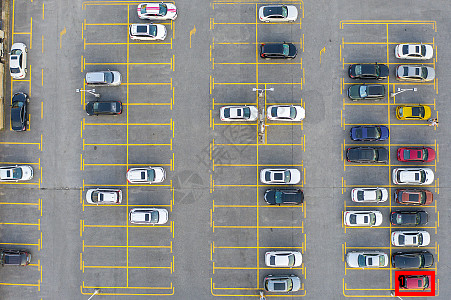


Thinking: False
模型回答：
 好的，我们来分析这张图片。

根据您的问题，我们将以图像中心为参考点，描述最右侧一列中位置最靠下的红色汽车。

1.  **定位汽车并报告边界框和分割掩码**

    目标车辆是位于图像最右侧一列、从下往上数第二辆的红色汽车。

    *   **边界框 (Bounding Box):** [878, 906, 963, 984]
    *   **分割掩码 (Segmentation Mask):** 由于我无法生成图像，此处无法提供分割掩码。

2.  **描述其相对于图像中心的位置**

    这辆红色的汽车位于整个图像的**右下角**区域。它处于图像水平方向的**右侧**，以及垂直方向的**下方**。

3.  **描述周围汽车及其相对位置**

    这辆红色汽车位于一个垂直的停车列中。
    *   它的**正上方**是一辆黑色的汽车。
    *   它的**正下方**是这一列的最后一辆车，是一辆白色的汽车。
    *   在它的**左侧**，是相邻的另一列停车位，该列中有一辆白色的汽车位于其大致相同的高度。

生成 Token: 265 | 耗时: 8.04s


{'answer': '好的，我们来分析这张图片。\n\n根据您的问题，我们将以图像中心为参考点，描述最右侧一列中位置最靠下的红色汽车。\n\n1.  **定位汽车并报告边界框和分割掩码**\n\n    目标车辆是位于图像最右侧一列、从下往上数第二辆的红色汽车。\n\n    *   **边界框 (Bounding Box):** [878, 906, 963, 984]\n    *   **分割掩码 (Segmentation Mask):** 由于我无法生成图像，此处无法提供分割掩码。\n\n2.  **描述其相对于图像中心的位置**\n\n    这辆红色的汽车位于整个图像的**右下角**区域。它处于图像水平方向的**右侧**，以及垂直方向的**下方**。\n\n3.  **描述周围汽车及其相对位置**\n\n    这辆红色汽车位于一个垂直的停车列中。\n    *   它的**正上方**是一辆黑色的汽车。\n    *   它的**正下方**是这一列的最后一辆车，是一辆白色的汽车。\n    *   在它的**左侧**，是相邻的另一列停车位，该列中有一辆白色的汽车位于其大致相同的高度。',
 'raw': '好的，我们来分析这张图片。\n\n根据您的问题，我们将以图像中心为参考点，描述最右侧一列中位置最靠下的红色汽车。\n\n1.  **定位汽车并报告边界框和分割掩码**\n\n    目标车辆是位于图像最右侧一列、从下往上数第二辆的红色汽车。\n\n    *   **边界框 (Bounding Box):** [878, 906, 963, 984]\n    *   **分割掩码 (Segmentation Mask):** 由于我无法生成图像，此处无法提供分割掩码。\n\n2.  **描述其相对于图像中心的位置**\n\n    这辆红色的汽车位于整个图像的**右下角**区域。它处于图像水平方向的**右侧**，以及垂直方向的**下方**。\n\n3.  **描述周围汽车及其相对位置**\n\n    这辆红色汽车位于一个垂直的停车列中。\n    *   它的**正上方**是一辆黑色的汽车。\n    *   它的**正下方**是这一列的最后一辆车，是一辆白色的汽车。\n    *   在它的**左侧**，是相邻的另一列停车位，该列中有一辆白色

In [5]:
question = FRAME + """
Find the bottommost red car in the rightmost parking column.

1. Locate the car and report its bounding box and segmentation mask.
2. Describe where it is relative to the CENTER of the image.
3. Describe the surrounding cars and their relative positions.

Answer the descriptions in Chinese.
"""

test(img1, question, thinking=False)

### 测试二——多目标定位
任务：找到图片2中所有明显呈蓝色的汽车，标记每辆车。

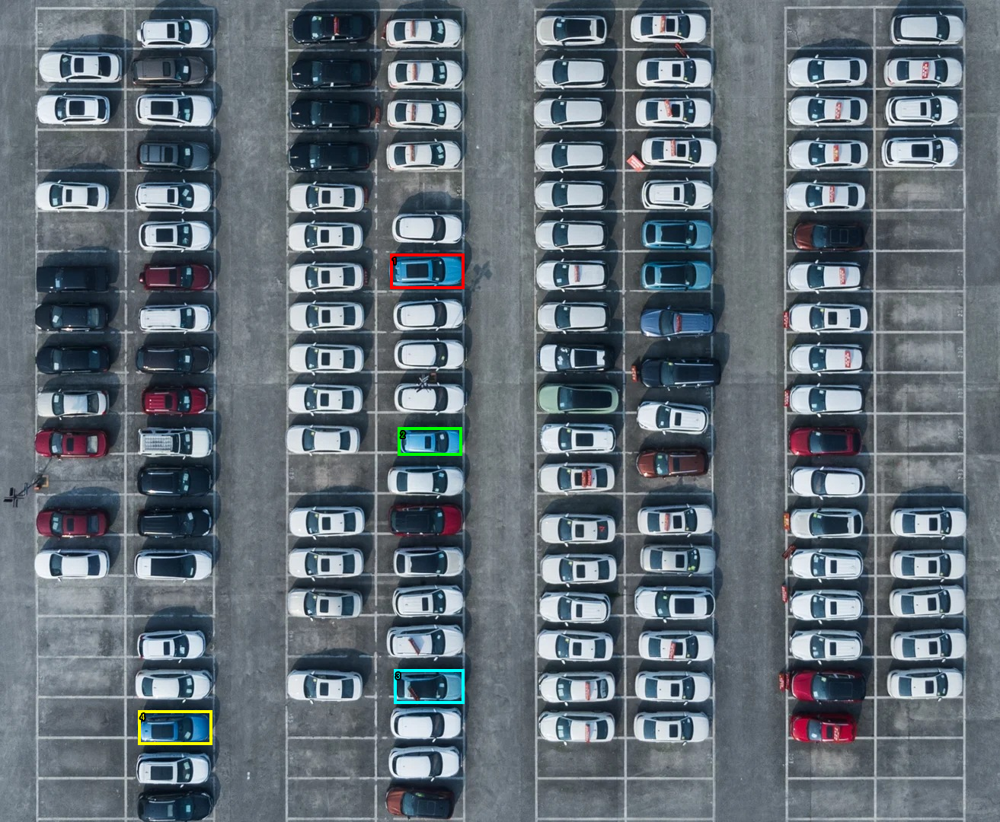


Thinking: False
模型回答：
 ```json
[
	{"bbox_2d": [390, 309, 464, 351], "label": "blue car"},
	{"bbox_2d": [398, 520, 462, 554], "label": "blue car"},
	{"bbox_2d": [394, 814, 464, 856], "label": "blue car"},
	{"bbox_2d": [138, 864, 212, 906], "label": "blue car"}
]
```

生成 Token: 151 | 耗时: 4.15s


{'answer': '```json\n[\n\t{"bbox_2d": [390, 309, 464, 351], "label": "blue car"},\n\t{"bbox_2d": [398, 520, 462, 554], "label": "blue car"},\n\t{"bbox_2d": [394, 814, 464, 856], "label": "blue car"},\n\t{"bbox_2d": [138, 864, 212, 906], "label": "blue car"}\n]\n```',
 'raw': '```json\n[\n\t{"bbox_2d": [390, 309, 464, 351], "label": "blue car"},\n\t{"bbox_2d": [398, 520, 462, 554], "label": "blue car"},\n\t{"bbox_2d": [394, 814, 464, 856], "label": "blue car"},\n\t{"bbox_2d": [138, 864, 212, 906], "label": "blue car"}\n]\n```\n',
 'boxes': [(390.0, 309.0, 464.0, 351.0),
  (398.0, 520.0, 462.0, 554.0),
  (394.0, 814.0, 464.0, 856.0),
  (138.0, 864.0, 212.0, 906.0)],
 'num_masks': 0,
 'tokens': 151,
 'seconds': 4.154947774994071,
 'incomplete': False}

In [6]:
question = FRAME + """
Find ALL cars with visibly blue body paint.
Do not include black or gray cars.

For each blue car:
1. Report its bounding box and segmentation mask.

Answer the descriptions in Chinese.
"""

test(img2, question, thinking=False)

### 测试三——空间比较与极值定位（关闭思考）
任务：在图片2的所有蓝色汽车中，找出画面最靠下的一辆。这里的“下”是相对画面中心而言，而非车辆的驾驶方向。

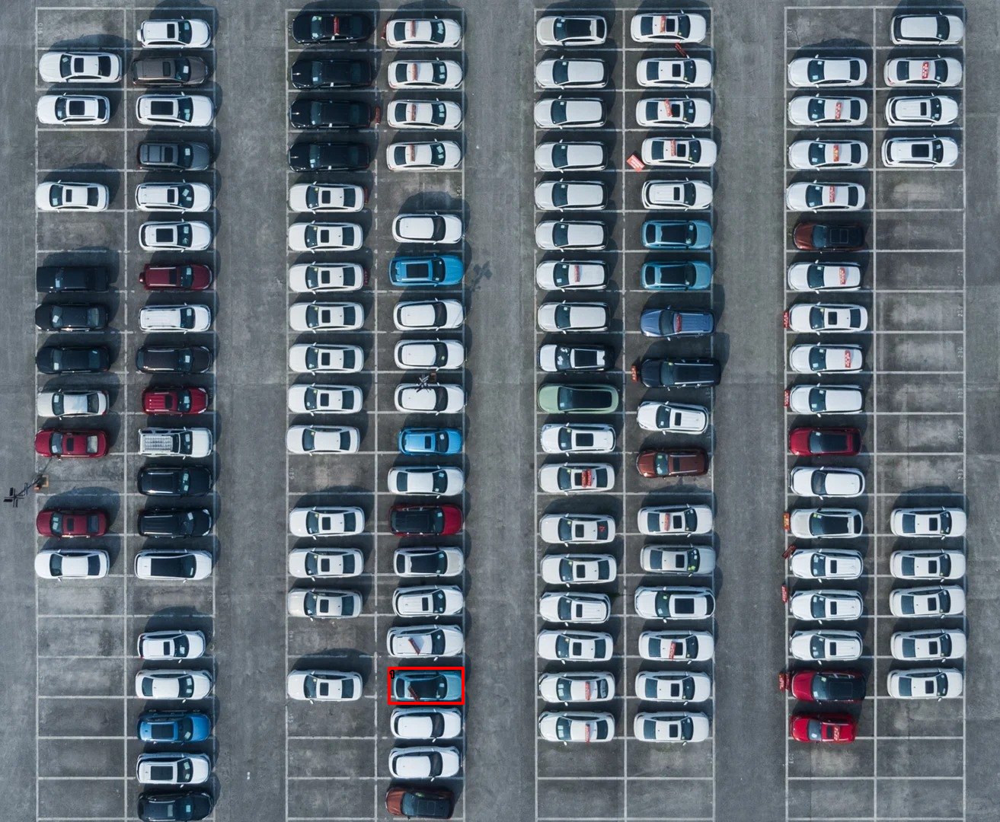


Thinking: False
模型回答：
 ```json
[
	{"bbox_2d": [388, 812, 464, 857], "label": "the one located lowest in the image"},
	{"bbox_2d": [388, 812, 464, 857], "label": "the one located lowest in the image"},
	{"bbox_2d": [388, 812, 464, 857], "label": "the one located lowest in the image"},
	{"bbox_2d": [388, 812, 464, 857], "label": "the one located lowest in the image"},
	{"bbox_2d": [388, 812, 464, 857], "label": "the one located lowest in the image"},
	{"bbox_2d": [388, 812, 464, 857], "label": "the one located lowest in the image"},
	{"bbox_2d": [388, 812, 464, 857], "label": "the one located lowest in the image"},
	{"bbox_2d": [388, 812, 464, 857], "label": "the one located lowest in the image"},
	{"bbox_2d": [388, 812, 464, 857], "label": "the one located lowest in the image"},
	{"bbox_2d": [388, 812, 464, 857], "label": "the one located lowest in the image"},
	{"bbox_2d": [388, 812, 464, 857], "label": "the one located lowest in the image"},
	{"bbox_2d": [388, 812, 464, 857], "label"

{'answer': '```json\n[\n\t{"bbox_2d": [388, 812, 464, 857], "label": "the one located lowest in the image"},\n\t{"bbox_2d": [388, 812, 464, 857], "label": "the one located lowest in the image"},\n\t{"bbox_2d": [388, 812, 464, 857], "label": "the one located lowest in the image"},\n\t{"bbox_2d": [388, 812, 464, 857], "label": "the one located lowest in the image"},\n\t{"bbox_2d": [388, 812, 464, 857], "label": "the one located lowest in the image"},\n\t{"bbox_2d": [388, 812, 464, 857], "label": "the one located lowest in the image"},\n\t{"bbox_2d": [388, 812, 464, 857], "label": "the one located lowest in the image"},\n\t{"bbox_2d": [388, 812, 464, 857], "label": "the one located lowest in the image"},\n\t{"bbox_2d": [388, 812, 464, 857], "label": "the one located lowest in the image"},\n\t{"bbox_2d": [388, 812, 464, 857], "label": "the one located lowest in the image"},\n\t{"bbox_2d": [388, 812, 464, 857], "label": "the one located lowest in the image"},\n\t{"bbox_2d": [388, 812, 464, 

In [7]:
question = FRAME + """
Among all visibly blue cars, find the one located lowest in the image.

1. Locate this car and report its bounding box and segmentation mask.
2. Describe its position relative to the CENTER of the image.
3. Explain its relative position compared with the other blue cars.
"""

test(img2, question, thinking=False)

### 测试三——空间比较与极值定位（开启思考）
任务：在图片2的所有蓝色汽车中，找出画面最靠下的一辆。这里的“下”是相对画面中心而言，而非车辆的驾驶方向。

In [8]:
question = FRAME + """
Among all visibly blue cars, find the one located lowest in the image.

1. Locate this car and report its bounding box and segmentation mask.
2. Describe its position relative to the CENTER of the image.
3. Explain its relative position compared with the other blue cars.
"""

test(img2, question, thinking=True)

思考尚未结束或生成被截断，可增大 max_new_tokens
原始输出：
 The user wants me to identify the lowest blue car in the image.

1.  **Scan for blue cars:** I need to look through the parking lot rows and columns to find cars that are blue.
    *   Looking at the second column from the left (counting the empty spaces as columns too, or just grouping by car rows):
        *   Row 4 (approx): There's a blue car.
        *   Row 10 (approx): There's a blue car.
        *   Row 12 (approx): There's a blue car.
        *   Row 14 (approx): There's a blue car.
    *   Looking at the fourth column from the left:
        *   Row 4 (approx): There's a blue car.
        *   Row 10 (approx): There's a blue car.
    *   Looking at the fifth column from the left:
        *   Row 14 (approx): There's a blue car.

2.  **Determine the "lowest" one:** "Lowest" means closest to the bottom edge of the image.
    *   Let's check the vertical position of the blue cars found.
    *   Blue car in column 2 (approx row 14): This is qu

{'answer': None,
 'raw': 'The user wants me to identify the lowest blue car in the image.\n\n1.  **Scan for blue cars:** I need to look through the parking lot rows and columns to find cars that are blue.\n    *   Looking at the second column from the left (counting the empty spaces as columns too, or just grouping by car rows):\n        *   Row 4 (approx): There\'s a blue car.\n        *   Row 10 (approx): There\'s a blue car.\n        *   Row 12 (approx): There\'s a blue car.\n        *   Row 14 (approx): There\'s a blue car.\n    *   Looking at the fourth column from the left:\n        *   Row 4 (approx): There\'s a blue car.\n        *   Row 10 (approx): There\'s a blue car.\n    *   Looking at the fifth column from the left:\n        *   Row 14 (approx): There\'s a blue car.\n\n2.  **Determine the "lowest" one:** "Lowest" means closest to the bottom edge of the image.\n    *   Let\'s check the vertical position of the blue cars found.\n    *   Blue car in column 2 (approx row 14):

### 测试四——多步空间关系推理（关闭思考）
任务：以图片2中部偏右的蓝色汽车 A 为参考，先向画面左侧移动一个停车位列，再向画面上方移动一个停车位行，找到 B。

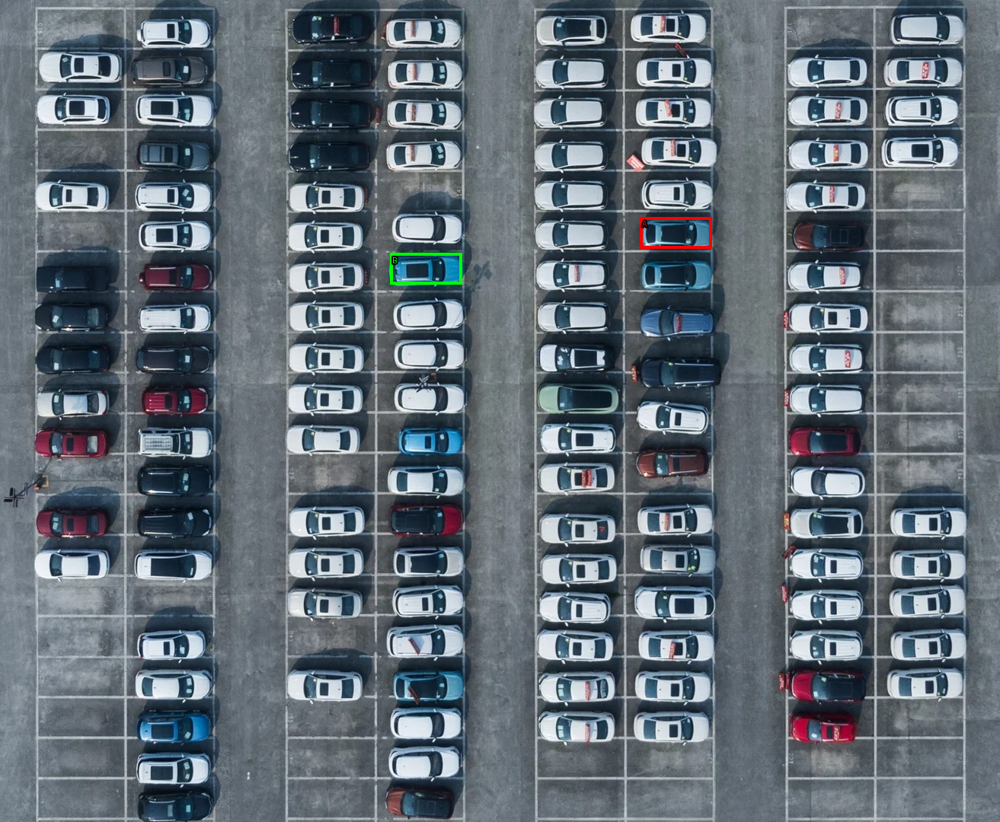


Thinking: False
模型回答：
 ```json
[
    {
        "bbox_2d": [
            640,
            264,
            712,
            302
        ],
        "mask": "image"
    },
    {
        "bbox_2d": [
            390,
            308,
            462,
            346
        ],
        "mask": "image"
    },
    {
        "bbox_2d": "B车是一辆浅蓝色的汽车，位于A车的左上方。",
        "bbox_2d": "B车位于整个图像的中心偏左上方。"
    }
]
```

生成 Token: 167 | 耗时: 4.55s


{'answer': '```json\n[\n    {\n        "bbox_2d": [\n            640,\n            264,\n            712,\n            302\n        ],\n        "mask": "image"\n    },\n    {\n        "bbox_2d": [\n            390,\n            308,\n            462,\n            346\n        ],\n        "mask": "image"\n    },\n    {\n        "bbox_2d": "B车是一辆浅蓝色的汽车，位于A车的左上方。",\n        "bbox_2d": "B车位于整个图像的中心偏左上方。"\n    }\n]\n```',
 'raw': '```json\n[\n    {\n        "bbox_2d": [\n            640,\n            264,\n            712,\n            302\n        ],\n        "mask": "image"\n    },\n    {\n        "bbox_2d": [\n            390,\n            308,\n            462,\n            346\n        ],\n        "mask": "image"\n    },\n    {\n        "bbox_2d": "B车是一辆浅蓝色的汽车，位于A车的左上方。",\n        "bbox_2d": "B车位于整个图像的中心偏左上方。"\n    }\n]\n```\n',
 'boxes': [(640.0, 264.0, 712.0, 302.0), (390.0, 308.0, 462.0, 346.0)],
 'num_masks': 0,
 'tokens': 167,
 'seconds': 4.550011852988973,
 'incomplete': False}

In [9]:
question = FRAME + """
In the middle-right area of the image, find the two bright blue cars
parked vertically next to each other.

Call the UPPER blue car A.

Starting from A:
1. Move ONE parking-space column toward IMAGE-LEFT.
2. Then move ONE parking-space row toward IMAGE-UP.
3. Call the car at the destination B.

Tasks:
1. Locate A and B, in that order, using bounding boxes and masks.
2. Describe the color and appearance of car B.
3. Describe where B is relative to A.
4. Describe where B is relative to the CENTER of the entire image.

If there is no car at the destination, state that explicitly.

Answer the descriptions in Chinese.
"""

test(img2, question, labels=["A", "B"], thinking=False)

### 测试四——多步空间关系推理（开启思考）
任务：以图片2中部偏右的蓝色汽车 A 为参考，先向画面左侧移动一个停车位列，再向画面上方移动一个停车位行，找到 B。

In [10]:
question = FRAME + """
In the middle-right area of the image, find the two bright blue cars
parked vertically next to each other.

Call the UPPER blue car A.

Starting from A:
1. Move ONE parking-space column toward IMAGE-LEFT.
2. Then move ONE parking-space row toward IMAGE-UP.
3. Call the car at the destination B.

Tasks:
1. Locate A and B, in that order, using bounding boxes and masks.
2. Describe the color and appearance of car B.
3. Describe where B is relative to A.
4. Describe where B is relative to the CENTER of the entire image.

If there is no car at the destination, state that explicitly.

Answer the descriptions in Chinese.
"""

test(img2, question, labels=["A", "B"], thinking=True)

思考尚未结束或生成被截断，可增大 max_new_tokens
原始输出：
 用户要求我根据提供的图像，找到两个特定的蓝色汽车，并执行一系列相对移动操作来定位另一辆车。

1.  **定位目标 A (Upper blue car):**
    *   用户描述：“在图像中间偏右的区域，找到两个垂直停放的亮蓝色汽车。”
    *   观察图像：图像是一个停车场俯视图。
    *   寻找蓝色汽车：
        *   左侧有一列蓝色车（第4列，从上往下数大概第5、6、10、11、12、13、14、15、16、17、18、19、20、21、22、23、24、25、26、27、28、29、30、31、32、33、34、35、36、37、38、39、40、41、42、43、44、45、46、47、48、49、50、51、52、53、54、55、56、57、58、59、60、61、62、63、64、65、66、67、68、69、70、71、72、73、74、75、76、77、78、79、80、81、82、83、84、85、86、87、88、89、90、91、92、93、94、95、96、97、98、99、100、101、102、103、104、105、106、107、108、109、110、111、112、113、114、115、116、117、118、119、120、121、122、123、124、125、126、127、128、129、130、131、132、133、134、135、136、137、138、139、140、141、142、143、144、145、146、147、148、149、150、151、152、153、154、155、156、157、158、159、160、161、162、163、164、165、166、167、168、169、170、171、172、173、174、175、176、177、178、179、180、181、182、183、184、185、186、187、188、189、190、191、192、193、194、195、196、197、198、199、200、201、202、203、204、205、206、207、208、209、210、211、212、213、214、215、216、217、218、219、220、221、22

{'answer': None,
 'raw': '用户要求我根据提供的图像，找到两个特定的蓝色汽车，并执行一系列相对移动操作来定位另一辆车。\n\n1.  **定位目标 A (Upper blue car):**\n    *   用户描述：“在图像中间偏右的区域，找到两个垂直停放的亮蓝色汽车。”\n    *   观察图像：图像是一个停车场俯视图。\n    *   寻找蓝色汽车：\n        *   左侧有一列蓝色车（第4列，从上往下数大概第5、6、10、11、12、13、14、15、16、17、18、19、20、21、22、23、24、25、26、27、28、29、30、31、32、33、34、35、36、37、38、39、40、41、42、43、44、45、46、47、48、49、50、51、52、53、54、55、56、57、58、59、60、61、62、63、64、65、66、67、68、69、70、71、72、73、74、75、76、77、78、79、80、81、82、83、84、85、86、87、88、89、90、91、92、93、94、95、96、97、98、99、100、101、102、103、104、105、106、107、108、109、110、111、112、113、114、115、116、117、118、119、120、121、122、123、124、125、126、127、128、129、130、131、132、133、134、135、136、137、138、139、140、141、142、143、144、145、146、147、148、149、150、151、152、153、154、155、156、157、158、159、160、161、162、163、164、165、166、167、168、169、170、171、172、173、174、175、176、177、178、179、180、181、182、183、184、185、186、187、188、189、190、191、192、193、194、195、196、197、198、199、200、201、202、203、204、205、206、207、208、209、210、211、212、213、214、215、216、217、218、219、220、221、222、223、2

### 总结
总体评价：模型具备基本的视觉目标识别与定位能力，但全局感知不完整、空间关系推理不可靠，且复杂任务中存在严重的重复生成问题。

一、各项测试结果

① 单目标定位	基本成功	准确定位右下角目标红车，BBox 较准确，方位判断正确。但错误描述其下方还有白车，说明局部场景关系理解不够准确。

② 多目标定位	部分成功	仅定位4辆蓝车，已输出的框基本正确，但遗漏右侧多辆明显的蓝车，存在严重漏检。

③ 空间比较与极值定位	失败	关闭 Thinking 时选错目标，并重复输出相同 BBox 直至8192 Token上限；开启 Thinking 后陷入冗长、重复的分析，未得到最终答案。

④ 多步空间关系推理	失败	关闭 Thinking 时生成了 A、B 定位框，但 B 定位错误，且文字中的“左上方”与定位框反映的“左下方”矛盾；开启 Thinking 后陷入大量无意义的停车列枚举，未完成任务。

二、值得关注的现象
1. 局部定位能力优于全局空间理解能力。
模型能够找到单个指定目标，也能够定位部分蓝车，但面对“找到所有蓝车”“选择最下方的蓝车”时表现明显下降。
尤其值得注意：测试二已经识别出左下方位置更低的蓝车，但测试三面对同一图片却选择了其他车辆，说明其全局空间比较能力不稳定。

2. Thinking 不仅没有改善结果，反而暴露出严重的生成稳定性问题。
测试三、四开启 Thinking 后均未完成任务，出现重复枚举、无意义内容不断扩展等现象。
这说明模型在复杂视觉空间任务中可能出现推理过程失控，不能简单认为增加思考长度就能提高正确率。

3. 模型的文字空间描述与视觉定位并不总是一致。
测试四中，模型声称 B 位于 A 左上方，但实际输出的 BBox 显示 B 位于 A 左下方。
这反映出模型的视觉定位结果与语言空间推理结果之间缺乏可靠的一致性。

四、核心结论
1. 基础视觉感知能力存在，但全局感知明显不足。 模型可以识别和定位局部目标，却难以保证复杂密集场景中目标搜索的完整性。

2. 空间推理能力不够可靠。 尤其是涉及目标筛选、空间比较、多步位置变换时，容易出现定位与推理不一致的问题。

3. 生成稳定性是突出短板。 Thinking 模式并未带来预期提升，反而在复杂任务中出现严重的重复生成与无法结束的问题。

4. 与 Xiaomi-Lens-0 相比，两者均存在明显短板。 Xiaomi-Lens-0 在部分复杂任务的完成度上表现稍好，但现有测试还不足以证明其空间理解能力获得了实质性提升。

最终判断：Qwen3.5-4B 已具备基础的视觉定位能力，但距离复杂场景下可靠的空间理解与多步推理仍有较大差距。尤其值得研究的是，模型究竟是“没有正确感知到目标”，还是“感知到了目标，却无法正确完成空间推理”。这也应当成为后续 VLM/VLN 实验重点区分的问题。